# EmPath environmental rasters and overlays
Run in **Python (EmPath)**. This is GIS preparation; notebook 07 contains the optional pretrained GeoAI step. Missing real inputs are reported, never replaced with demo values. Raw inputs are not modified.

**Goal:** separate environmental columns on blocks and graph edges, not an unexplained merged friction score.

**Status:** ZIP preview is not a cleaning result. Actual Census blocks are now configured. The canopy clip is now configured. Temperature raster remains absent; NOAA station weather is packaged separately in notebook 08. Check the inventory and run report before interpreting any map.

In [1]:
# Local workaround for inherited incompatible Anaconda PROJ/GDAL paths.
# Affects this notebook kernel only; does not change machine-wide settings.
import os
os.environ.pop('PROJ_DATA', None)
os.environ.pop('GDAL_DATA', None)
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'scripts/environment_pipeline.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts/environment_pipeline.py').exists(), 'Open from EmPath or its notebooks folder.'
sys.path.insert(0, str(ROOT / 'scripts'))
import environment_pipeline as ep
config = json.loads((ROOT / 'config/environment_pipeline.json').read_text())
print('Python:', sys.executable)


Python: /Users/nalinikantheti/Documents/ChatGPT/EmPath/.venv/bin/python


## 1 Inspect inputs
Set file paths in `config/environment_pipeline.json`, then rerun setup. Canopy: a clipped percent GeoTIFF. Temperature: georeferenced data with verified units, scale/offset, valid range and observation date. Blocks: actual 2020 census blocks with unique 15-digit GEOID20—not the existing block-group screening map. Shapefile, zipped shapefile, GeoJSON and GeoPackage are supported by GeoPandas.

Use Census TIGER/Line blocks: https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2020.html . Download the Texas block file or complete county extracts covering the scope; the run report checks block-area coverage per ZIP. No automatic statewide download occurs.

,input,path,status
0,census_blocks,data/processed/census_blocks_2020/blocks.gpkg,ready
1,canopy,None,missing
2,temperature,None,missing


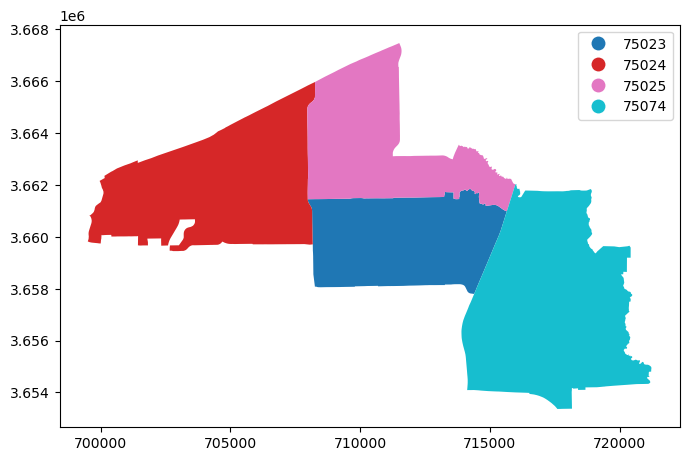

In [2]:
display(ep.inventory(config))
scope = ep.read_scope(config)
scope.to_crs(26914).plot(column="ZCTA5", legend=True, figsize=(8, 6));

## Census block boundaries
This shows actual 2020 census blocks inside the four ZIPs. Block outlines can be drawn without environmental rasters. Later cells color these blocks by raster-derived attributes. To refresh the official cached block download: `env -u PROJ_DATA -u GDAL_DATA .venv/bin/python scripts/download_census_blocks.py`.

2,862 block polygons with positive area inside the scope


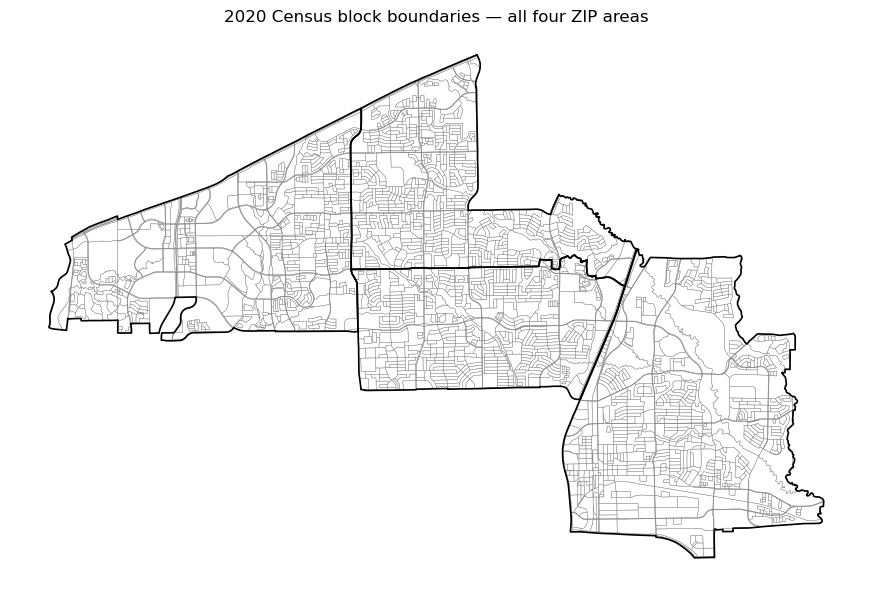

In [3]:
if config.get('blocks') and ep.resolve(config['blocks']).exists():
    block_boundaries = ep.prepare_blocks(config, scope)
    print(f'{len(block_boundaries):,} block polygons with positive area inside the scope')
    ax = block_boundaries.boundary.plot(color='gray', linewidth=.25, figsize=(11,8))
    scope.to_crs(block_boundaries.crs).boundary.plot(ax=ax, color='black', linewidth=1.2)
    ax.set_axis_off()
    ax.set_title('2020 Census block boundaries — all four ZIP areas')
else:
    print('Census blocks missing: run scripts/download_census_blocks.py first.')

## 2 Clean, classify and summarize
The pipeline clips each raster in its native grid, applies its source scale/offset, masks NoData and configured out-of-range values, and records metadata. No silent resampling or unit conversion.

Optional vector classes are display bands, not learned classes. Blocks receive pixel-center means/min/max and coverage indicators. Partial edge summaries default to 200 deterministic sample edges for a quick check; increase `edge_sample_limit` to the full edge count only after inspection. A 10 m corridor is a scenario choice, not measured sidewalk width.

If the source stores scale/offset outside GeoTIFF metadata (e.g. some Landsat products), set explicit `scale` and `offset` in its raster config. Apply cloud/quality masks before this generic cleaner.

In [4]:
report = ep.run(config)
print(json.dumps(report, indent=2))

{
  "created_utc": "2026-11-12T03:06:48.260754+00:00",
  "inventory": [
    {
      "input": "census_blocks",
      "path": "data/processed/census_blocks_2020/blocks.gpkg",
      "status": "ready"
    },
    {
      "input": "canopy",
      "path": null,
      "status": "missing"
    },
    {
      "input": "temperature",
      "path": null,
      "status": "missing"
    }
  ],
  "rasters": {},
  "warnings": [
    "canopy: missing input; skipped, no synthetic substitute.",
    "temperature: missing input; skipped, no synthetic substitute."
  ],
  "ai_inference_performed": false,
  "block_coverage_by_zip": [
    {
      "zcta": "75023",
      "block_area_coverage": 0.9999999999999997
    },
    {
      "zcta": "75024",
      "block_area_coverage": 0.9999999999999993
    },
    {
      "zcta": "75025",
      "block_area_coverage": 1.0000000000000004
    },
    {
      "zcta": "75074",
      "block_area_coverage": 1.0000000000000004
    }
  ],
  "notes": [
    "Native raster grids retaine

## 3 Inspect the merged block map
Each raster becomes separate columns. Missing statistics remain missing. Pixel-center summaries are approximate; small blocks may contain no pixel centers. `valid_center_fraction` describes available centers inside the raster; check `raster_overlap_fraction` as well. For precise partial-pixel weighting, consider exactextract.

In [5]:
import geopandas as gpd
out = ep.resolve(config['output'])
path = out / 'block_environment.gpkg'
if path.exists() and 'block_coverage_by_zip' in report:
    blocks = gpd.read_file(path)
    display(blocks.drop(columns='geometry').head())
    for column in [c for c in blocks if c.endswith('_mean')]:
        ax = blocks.plot(column=column, legend=True, figsize=(9,6),
                         missing_kwds={'color':'lightgray', 'label':'Missing'})
        scope.to_crs(blocks.crs).boundary.plot(ax=ax, color='black', linewidth=.8)
        ax.set_title(column + ' — source resolution retained')
        ax.figure.savefig(out / (column + '_blocks.png'), dpi=160, bbox_inches='tight')
else:
    print('Supply census blocks to create the block summary map.')

,OBJECTID,GEOID,STATE,COUNTY,TRACT,BLOCK,GEOID20,geometry_repaired,scope_area_fraction
0,15703,480850320131001,48,085,032013,1001,480850320131001,False,1.0
1,15707,480850320121008,48,085,032012,1008,480850320121008,False,1.0
2,15709,480850316112014,48,085,031611,2014,480850316112014,False,1.0
3,15713,480850316361000,48,085,031636,1000,480850316361000,False,1.0
4,15714,480850316361006,48,085,031636,1006,480850316361006,False,1.0


## 4 Inspect the edge attributes
Join to the graph using `(u, v, key)`, never row order. Keep existing lengths and alternative paths. Do not call these AI-learned friction weights. The final edge cost needs a documented rule or calibrated model; census-block averages should not replace available edge-level measurements.

In [6]:
import pandas as pd
path = out / 'edge_environment_sample.csv'
if path.exists() and 'edge_sample' in report:
    display(pd.read_csv(path).head())
else:
    print('No edge feature table yet: supply a valid raster first.')

No edge feature table yet: supply a valid raster first.


## 5 Export the edge inspection maps
Each available environmental attribute gets its own map. Gray background shows ZIP boundaries; sample edges are labeled as a sample. Missing edge values remain gray. These are feature maps, not completed friction maps.

In [7]:
path = out / 'edge_environment_sample.gpkg'
if path.exists() and 'edge_sample' in report:
    edges = gpd.read_file(path)
    for column in [c for c in edges if c.endswith('_mean')]:
        ax = scope.to_crs(edges.crs).boundary.plot(color='gray', linewidth=.6, figsize=(9,6))
        edges.plot(ax=ax, color='lightgray', linewidth=1)
        if edges[column].notna().any():
            edges[edges[column].notna()].plot(ax=ax, column=column, legend=True, linewidth=2)
        ax.set_title(column + ' — sampled walking edges')
        ax.figure.savefig(out / (column + '_edges.png'), dpi=160, bbox_inches='tight')
else:
    print('Edge map awaits raster inputs; no synthetic map created.')

Edge map awaits raster inputs; no synthetic map created.


## Deliverables and checks
- `*_clean.tif`: georeferenced cleaned rasters.
- `*_classes.gpkg`: optional classified display polygons.
- `block_environment.gpkg` and CSV: blocks with separate environmental features.
- `edge_environment_sample.gpkg` and CSV: sample walking edges with features and coverage flags.
- `run_report.json`: provenance, scope coverage and skipped/missing inputs.

Do not treat air temperature, satellite surface temperature and canopy as interchangeable. Different dates remain explicit. Outputs are environmental attributes—not validated heat stress, time-specific shade, or routing safety. This notebook does not repair network topology or entrances.

Libraries: [Rasterio](https://rasterio.readthedocs.io/en/stable/topics/features.html), [GeoPandas](https://geopandas.org/en/stable/docs/user_guide/set_operations.html).